# Supplementary Fig. 9: effect of the drift correction on the yield of single-units

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce Supplementary Fig. 9: proportions (and counts) of single-units (white) and multi-units (black) sorted by Kilosort 4, 3 and 2.5 with ("+") and without ("-") drift correction for the Marques-Smith recording (M), the biophysical model in the spontaneous regime (NS) and Buccino's synthetic model (S); "+ (V100)": original sortings on a Tesla V100 GPU, "+/- (rtx5090)": re-runs on an RTX 5090 GPU.

**source data**: `figures/8_source_data/supp_fig9/supp_fig9.xlsx` (sheet `unit_counts`: the number of single-units and multi-units of each of the 27 bars; sheet `check_v100_recomputed`: the V100 column recomputed from the stored sortings). The counts are those annotated on the bars of the paper's figure (text of the paper's pdf); the sortings of the RTX 5090 columns are not stored.

Run time: about 5 seconds.

In [1]:
# SETUP PACKAGES
import os
import warnings
import pandas as pd
from matplotlib import pyplot as plt
warnings.filterwarnings("ignore")

# SET PROJECT PATH
PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.validation import drift_correction_yield as dc

SOURCE_DATA = "figures/8_source_data/supp_fig9/supp_fig9.xlsx"

# SETUP PLOT
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5
plt.rcParams["axes.linewidth"] = 0.5
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
savefig_cfg = {"transparent": True, "dpi": 400}

## Load the source data

In [2]:
df = pd.read_excel(SOURCE_DATA, sheet_name="unit_counts")
display(df[["sorter", "dataset", "condition", "single_units", "multi_units"]].pivot(index=["sorter", "dataset"], columns="condition", values=["single_units", "multi_units"]).loc[[(s, d) for s in dc.SORTERS for d in dc.DATASETS]])

single_units                         multi_units              \
condition          + (V100) + (rtx5090) - (rtx5090)    + (V100) + (rtx5090)   
sorter dataset                                                                
ks4    M                 96          92          97         104         100   
       NS               184         206         240         336         367   
       S                377         359         334         163         153   
ks3    M                111         112         110         164         134   
       NS               233         222         238         570         495   
       S                349         349         355         166         177   
ks2.5  M                186         179         167         905         903   
       NS               578         378         386         958         489   
       S                349         349         355         166         177   

                            
condition      - (rtx5090)  
sorter dataset              
ks4    M               105  
       NS              363  
       S               174  
ks3    M               134  
       NS              508  
       S               189  
ks2.5  M               927  
       NS              470  
       S               189

## Check: V100 column recomputed from the stored sortings

In [3]:
display(pd.read_excel(SOURCE_DATA, sheet_name="check_v100_recomputed"))

,sorter,dataset,condition,single_units,multi_units,total_units,proportion_single_units,proportion_multi_units,single_units_local,multi_units_local,same_as_paper
0,ks4,M,+ (V100),96,104,200,0.480000,0.520000,96,104,True
1,ks4,NS,+ (V100),184,336,520,0.353846,0.646154,184,336,True
2,ks4,S,+ (V100),377,163,540,0.698148,0.301852,377,163,True
3,ks3,M,+ (V100),111,164,275,0.403636,0.596364,111,164,True
4,ks3,NS,+ (V100),233,570,803,0.290162,0.709838,233,570,True
5,ks3,S,+ (V100),349,166,515,0.677670,0.322330,349,166,True
6,ks2.5,M,+ (V100),186,905,1091,0.170486,0.829514,186,905,True
7,ks2.5,NS,+ (V100),578,958,1536,0.376302,0.623698,578,958,True
8,ks2.5,S,+ (V100),349,166,515,0.677670,0.322330,413,1162,False


## Plot, same as the paper

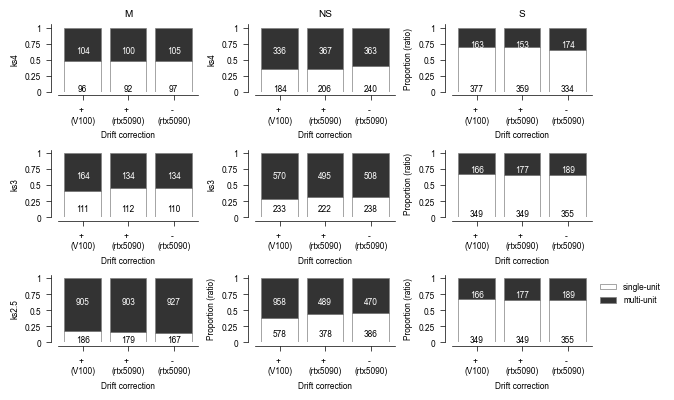

In [4]:
fig = dc.plot_source_data(df)
plt.savefig(SOURCE_DATA.replace(".xlsx", ".svg"), bbox_inches="tight", **savefig_cfg)